# Tarefa 1: análise exploratória dos dados

A tarefa 1 do TrafficFlowBench pede velocidade e fluxo nas células (detector × instante de 5 minutos) que os organizadores apagaram da camada publicada. Este notebook olha os dados antes de qualquer modelo: o que existe, quanto falta, que evidência sobra em volta de cada alvo e quanto métodos simples já acertam.

As células são lidas dos parquets em `data/raw/trafficflowbench` (`make data`) e organizadas em cubos `[dia, intervalo de 5 min, estação]` por corredor e split, guardados em `data/interim/tarefa1_cubos/` (fora do git, ~3 GB). A primeira execução monta os cubos em poucos minutos; as seguintes reaproveitam.

**Principais achados**

- As falhas de medição seguem o mesmo processo nos dez corredores: 16,5% das células ficam sem valor e 76,4% são elegíveis (`pct_observed >= 75`). Metade das falhas dura um único intervalo de 5 minutos.
- Os alvos são as células elegíveis apagadas: exatamente 20%, 30% ou 50% delas, conforme o regime do dia. Mais da metade dos alvos tem a mesma estação visível 5 minutos antes, e a observação mais próxima está, em média, a 6,5 minutos.
- Na validação e no privado, ~2% dos alvos caem nos apagões de 90 minutos em volta das janelas da tarefa 2, que o treino não tem.
- Os corredores vão de quase sempre livres (D7_I10_W, 0,4% das células em fila) a muito congestionados (D7_I405_N, 9,7%). O padrão semanal é fraco e não há tendência entre os meses.
- Os dados seguem um diagrama fundamental triangular: em fila, velocidade e fluxo de uma célula estão amarrados.
- Células inelegíveis têm o mesmo ruído das completas e servem de evidência. Só o ruído de medida (σ ≈ 1,9 km/h e 32 veic/h/faixa) já limita o score a cerca de 0,935.
- No treino, a média histórica (a ideia do baseline oficial) faz 0,720. Interpolar no tempo faz 0,909, e tirar a velocidade do tempo e o fluxo da média entre tempo e espaço, 0,915.

## A métrica

Para cada corredor e regime de máscara (R1, R2 e R3 apagam 20%, 30% e 50% das células elegíveis):

$$S = 0{,}54\,\max\!\Big(0,\ 1-\frac{\mathrm{RMSE}_v}{25}\Big) + 0{,}46\,\max\!\Big(0,\ 1-\frac{\mathrm{RMSE}_q}{600}\Big)$$

com $v$ em km/h e $q$ em veículos/h **por faixa**: o fluxo previsto e o verdadeiro são divididos pelas `lanes` de `network/fd_parameters.csv` antes do erro. O score do corredor é a média dos três regimes; o geral é a média das cinco famílias (I-10, I-210, I-405 do D7, I-5 e I-405 do D12), cada uma a média das suas duas direções. Só contam células com `pct_observed >= 75`. A função `s_state` abaixo reproduz `src/task1/score_task1.py` do repositório oficial.

In [1]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REL = RAIZ / "data/raw/trafficflowbench/kaggle_public"
CUBOS = RAIZ / "data/interim/tarefa1_cubos"
PAINEIS = sorted(p.name for p in (REL / "corridors").iterdir())
SPLITS = ("train", "validation", "private")
REGIMES = ("R1", "R2", "R3")

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Estilo dos gráficos: tinta neutra, eixos discretos, uma rampa azul para magnitudes.
TINTA, TINTA_2, TINTA_MUDA = "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO, SUPERFICIE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO, "axes.linewidth": 0.8, "axes.labelcolor": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "grid.color": GRADE, "grid.linewidth": 0.8,
    "xtick.color": TINTA_MUDA, "ytick.color": TINTA_MUDA, "xtick.labelcolor": TINTA_2,
    "ytick.labelcolor": TINTA_2, "text.color": TINTA, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
    "figure.dpi": 110, "legend.frameon": False,
})


def s_state(pv, pq_, tv, tq, faixas):
    # Score de um corredor/regime, como no avaliador oficial.
    rmse_v = np.sqrt(np.mean((pv - tv) ** 2))
    rmse_q = np.sqrt(np.mean(((pq_ - tq) / faixas) ** 2))
    return rmse_v, rmse_q, 0.54 * max(0, 1 - rmse_v / 25) + 0.46 * max(0, 1 - rmse_q / 600)


def familia(painel):
    return painel.rsplit("_", 1)[0]

### Montagem dos cubos

Cada arquivo parquet é um dia de um corredor: 288 instantes × número de estações. No treino há duas camadas, a completa (`mainline_states`) e a publicada com os alvos apagados (`mainline_states_masked`); na validação e no privado só existe a publicada. Os alvos vêm do template `task1/<PAINEL>/<split>/sample_submission_state.csv`. As estações ficam na ordem do corredor (`order_index` de `lwr_mainline_topology.csv`), que coincide com a ordem do `milepost`.

In [2]:
COLS = ["timestamp", "station_id", "speed_kmh", "flow_vph", "pct_observed", "is_score_eligible"]


def ordem_estacoes(painel):
    topo = pd.read_csv(REL / f"corridors/{painel}/network/lwr_mainline_topology.csv")
    f = sorted((REL / f"corridors/{painel}/train/mainline_states").glob("*/*.parquet"))[0]
    st = pq.read_table(f, columns=["station_id", "link_id", "milepost"]).to_pandas()
    st = st.drop_duplicates("station_id").merge(topo[["link_id", "order_index"]], on="link_id")
    return st.sort_values(["order_index", "milepost"]).reset_index(drop=True)


def intervalo(ts):
    # Índice 0..287 do instante, lido do texto YYYY-MM-DDTHH:MM:SSZ sem converter para data.
    return ts.str.slice(11, 13).astype(int).to_numpy() * 12 + ts.str.slice(14, 16).astype(int).to_numpy() // 5


def le_dia(path, idx, n):
    t = pq.read_table(path, columns=COLS).to_pandas()
    i, j = intervalo(t.timestamp), t.station_id.map(idx).to_numpy()
    out = {}
    for c, tipo, vazio in [("speed_kmh", np.float32, np.nan), ("flow_vph", np.float32, np.nan),
                           ("pct_observed", np.int8, -1), ("is_score_eligible", np.int8, -1)]:
        a = np.full((288, n), vazio, dtype=tipo)
        a[i, j] = t[c].to_numpy()
        out[c] = a
    return out


def monta_cubo(painel, split):
    destino = CUBOS / f"{painel}_{split}.npz"
    if destino.exists():
        return destino.name
    st = ordem_estacoes(painel)
    idx, n = dict(zip(st.station_id, range(len(st)))), len(st)
    base = REL / f"corridors/{painel}/{split}"
    mascarados = sorted(base.glob("mainline_states_masked/*/*.parquet"), key=lambda p: p.name)
    completos = {p.name: p for p in base.glob("mainline_states/*/*.parquet")}
    dias = [p.stem.removeprefix("synthetic_mainline_").replace("_", "-") for p in mascarados]
    D = len(dias)
    v, q, vo, qo = (np.empty((D, 288, n), np.float32) for _ in range(4))
    pct, eleg = (np.empty((D, 288, n), np.int8) for _ in range(2))
    for d, pm in enumerate(mascarados):
        pub = le_dia(pm, idx, n)
        ver = le_dia(completos[pm.name], idx, n) if split == "train" else pub
        v[d], q[d], pct[d], eleg[d] = ver["speed_kmh"], ver["flow_vph"], ver["pct_observed"], ver["is_score_eligible"]
        vo[d], qo[d] = pub["speed_kmh"], pub["flow_vph"]
    tpl = pd.read_csv(REL / f"task1/{painel}/{split}/sample_submission_state.csv",
                      usecols=["timestamp", "station_id"])
    alvo = np.zeros((D, 288, n), bool)
    dia_idx = {d: k for k, d in enumerate(dias)}
    alvo[tpl.timestamp.str.slice(0, 10).map(dia_idx).to_numpy(), intervalo(tpl.timestamp),
         tpl.station_id.map(idx).to_numpy()] = True
    np.savez(destino, v=v, q=q, v_pub=vo, q_pub=qo, pct=pct, eleg=eleg, alvo=alvo, dias=np.array(dias),
             regime=np.array([p.parent.name.removeprefix("mask_regime=") for p in mascarados]),
             station_id=st.station_id.to_numpy(), link_id=st.link_id.to_numpy(),
             milepost=st.milepost.to_numpy(), n_template=len(tpl))
    return destino.name


CUBOS.mkdir(parents=True, exist_ok=True)
with ProcessPoolExecutor(3) as ex:  # 3 processos cabem em ~7 GB de RAM
    feitos = list(ex.map(monta_cubo, *zip(*[(p, s) for p in PAINEIS for s in SPLITS])))
print(len(feitos), "cubos em", CUBOS.relative_to(RAIZ))


def carrega(painel, split="train"):
    z = np.load(CUBOS / f"{painel}_{split}.npz", allow_pickle=True)
    return {k: z[k] for k in z.files}


def rede(painel, link_ids):
    # Parâmetros por link na ordem das estações do cubo.
    fd = pd.read_csv(REL / f"corridors/{painel}/network/fd_parameters.csv").set_index("link_id")
    return fd.reindex(link_ids)

30 cubos em data/interim/tarefa1_cubos


## 1. Os corredores

Dez painéis direcionais, cada estação associada a um link da rede. Os números de faixas aparecem em duas fontes que discordam: `fd_parameters.csv` (a que o avaliador usa) e `lwr_mainline_topology.csv`.

In [3]:
linhas = []
for p in PAINEIS:
    z = carrega(p, "validation")
    fd = rede(p, z["link_id"])
    topo = pd.read_csv(REL / f"corridors/{p}/network/lwr_mainline_topology.csv").set_index("link_id")
    topo = topo.reindex(z["link_id"])
    linhas.append({
        "painel": p, "estações": len(fd), "extensão_km": fd.length_km.sum(),
        "faixas_fd": f"{fd.lanes.min():.0f}–{fd.lanes.max():.0f}",
        "faixas_divergentes_%": 100 * (fd.lanes.to_numpy() != topo.lanes.to_numpy()).mean(),
        "v_livre_kmh": f"{fd.free_speed_kmh.min():.0f}–{fd.free_speed_kmh.max():.0f}",
        "cap_por_faixa": (fd.capacity_vph / fd.lanes).median(),
    })
pd.DataFrame(linhas).set_index("painel").round(1)

,estações,extensão_km,faixas_fd,faixas_divergentes_%,v_livre_kmh,cap_por_faixa
painel,,,,,,
D12_I405_N,89,45.3,3–8,61.8,111–121,2102.8
D12_I405_S,44,32.7,4–8,56.8,112–121,2231.0
D12_I5_N,258,72.6,3–6,82.6,110–125,2104.8
D12_I5_S,100,45.0,3–6,78.0,110–126,2089.2
D7_I10_E,146,55.6,1–6,37.7,105–128,1918.8
D7_I10_W,107,49.1,3–6,30.8,105–126,2028.6
D7_I210_E,297,81.3,1–6,34.0,105–123,1918.8
D7_I210_W,81,44.5,2–6,22.2,105–127,1947.6
D7_I405_N,352,67.2,3–6,52.8,105–127,1918.8


## 2. Cobertura e qualidade

Cada célula traz `pct_observed`, a fração do intervalo de 5 minutos em que o detector respondeu. Células abaixo de 75% continuam publicadas (quando têm valor), mas não são pontuadas.

In [4]:
def sequencias(mask_1d):
    # Comprimentos das sequências de True de um vetor booleano.
    m = np.diff(np.concatenate([[0], mask_1d.astype(np.int8), [0]]))
    return np.flatnonzero(m == -1) - np.flatnonzero(m == 1)


cobertura, dist_pct = [], []
for p in PAINEIS:
    z = carrega(p)
    ausente = np.isnan(z["v"])
    seq = np.concatenate([sequencias(ausente[d, :, s]) for d in range(0, ausente.shape[0], 7)
                          for s in range(ausente.shape[2])])
    cobertura.append({
        "painel": p, "dias": ausente.shape[0], "células_M": ausente.size / 1e6,
        "sem_valor_%": 100 * ausente.mean(), "pct_lt_75_%": 100 * (z["pct"] < 75).mean(),
        "elegíveis_%": 100 * (z["eleg"] == 1).mean(),
        "falha_mediana_min": 5 * np.median(seq), "falha_p90_min": 5 * np.percentile(seq, 90),
        "falha_max_min": 5 * seq.max(),
    })
    valores, contagem = np.unique(z["pct"], return_counts=True)
    dist_pct.append(pd.Series(100 * contagem / z["pct"].size, index=valores, name=p))
display(pd.DataFrame(cobertura).set_index("painel").round(2))
print("Distribuição de pct_observed (% das células do treino):")
pd.DataFrame(dist_pct).round(1)

,dias,células_M,sem_valor_%,pct_lt_75_%,elegíveis_%,falha_mediana_min,falha_p90_min,falha_max_min
painel,,,,,,,,
D12_I405_N,273,7.00,16.53,23.6,76.4,5.0,10.0,115
D12_I405_S,273,3.46,16.53,23.6,76.4,5.0,10.0,115
D12_I5_N,273,20.28,16.53,23.6,76.4,5.0,10.0,150
D12_I5_S,273,7.86,16.53,23.6,76.4,5.0,10.0,135
D7_I10_E,273,11.48,16.53,23.6,76.4,5.0,10.0,115
D7_I10_W,273,8.41,16.53,23.6,76.4,5.0,10.0,145
D7_I210_E,273,23.35,16.53,23.6,76.4,5.0,10.0,140
D7_I210_W,273,6.37,16.53,23.6,76.4,5.0,10.0,130
D7_I405_N,273,27.68,16.53,23.6,76.4,5.0,10.0,150


Distribuição de pct_observed (% das células do treino):


,0,20,25,33,40,50,60,67,75,80,83,100
D12_I405_N,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D12_I405_S,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D12_I5_N,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D12_I5_S,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I10_E,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I10_W,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I210_E,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I210_W,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I405_N,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4
D7_I405_S,16.5,1.2,0.1,0.4,0.5,1.1,3.2,0.6,5.8,4.5,2.6,63.4


O processo de falhas é o mesmo nos dez corredores: 16,5% das células sem valor, 23,6% abaixo de 75% e 76,4% elegíveis, com a mesma distribuição de `pct_observed` até a terceira casa. As falhas são curtas (mediana de um intervalo, as mais longas na casa de duas horas) e nenhum detector fica fora o dia inteiro. É a assinatura de um gerador sintético que sorteia a disponibilidade de cada detector de forma independente do corredor.

## 3. A máscara e a evidência em volta dos alvos

No treino, os alvos do template são exatamente as células elegíveis apagadas na camada publicada. Cada dia pertence a um único regime.

In [5]:
regimes = []
for p in PAINEIS:
    z = carrega(p)
    apagada = np.isnan(z["v_pub"]) & ~np.isnan(z["v"])
    eleg = z["eleg"] == 1
    assert z["alvo"].sum() == z["n_template"], "template com células repetidas ou fora do cubo"
    assert not (z["alvo"] & ~eleg).any() and not (apagada & eleg & ~z["alvo"]).any()
    for r in REGIMES:
        d = z["regime"] == r
        regimes.append({"painel": p, "regime": r, "dias": int(d.sum()),
                        "alvos_sobre_elegíveis_%": 100 * z["alvo"][d].sum() / eleg[d].sum()})
pd.DataFrame(regimes).pivot(index="painel", columns="regime").round(1)

dias           alvos_sobre_elegíveis_%            
regime       R1   R2   R3                      R1    R2    R3
painel                                                       
D12_I405_N   87   94   92                    20.0  30.0  50.1
D12_I405_S   70   88  115                    20.1  30.0  50.0
D12_I5_N     96   84   93                    20.0  30.0  49.8
D12_I5_S     74  105   94                    19.9  30.0  50.0
D7_I10_E     99   95   79                    19.9  30.0  49.9
D7_I10_W     98   77   98                    20.0  30.0  49.9
D7_I210_E    94   77  102                    19.9  30.0  49.9
D7_I210_W    85  114   74                    19.9  29.9  50.0
D7_I405_N    82   99   92                    20.0  30.0  49.8
D7_I405_S    89  105   79                    20.0  30.0  49.9

Quanto sobra de informação para reconstruir cada alvo? A tabela mede, sobre os alvos, se a mesma estação está visível 5 minutos antes ou depois, se as estações vizinhas no corredor estão visíveis no mesmo instante, a distância média até a observação visível mais próxima na mesma estação e a fração de alvos em instantes em que o corredor inteiro está apagado.

In [6]:
def distancia_visivel(vis):
    # Distância, em intervalos, até a célula visível mais próxima na mesma estação e dia.
    T = vis.shape[1]
    idx = np.arange(T, dtype=np.int32)[None, :, None]
    antes = np.maximum.accumulate(np.where(vis, idx, -10_000), axis=1)
    depois = np.minimum.accumulate(np.where(vis, idx, 20_000)[:, ::-1], axis=1)[:, ::-1]
    return np.minimum(idx - antes, depois - idx)


def desloca(a, eixo, passo):
    out = np.zeros_like(a)
    origem = [slice(None)] * 3
    dest = [slice(None)] * 3
    origem[eixo] = slice(None, -passo) if passo > 0 else slice(-passo, None)
    dest[eixo] = slice(passo, None) if passo > 0 else slice(None, passo)
    out[tuple(dest)] = a[tuple(origem)]
    return out


evid = []
for p in PAINEIS:
    for split in SPLITS:
        z = carrega(p, split)
        vis, a = ~np.isnan(z["v_pub"]), z["alvo"]
        ant, dep = desloca(vis, 1, 1), desloca(vis, 1, -1)
        mont, jus = desloca(vis, 2, 1), desloca(vis, 2, -1)
        corredor_apagado = np.broadcast_to(~vis.any(axis=2, keepdims=True), vis.shape)
        evid.append({
            "painel": p, "split": split, "alvos": int(a.sum()), "visíveis_%": 100 * vis.mean(),
            "t-5min_%": 100 * ant[a].mean(), "t+5min_%": 100 * dep[a].mean(),
            "ambos_%": 100 * (ant & dep)[a].mean(), "montante_%": 100 * mont[a].mean(),
            "jusante_%": 100 * jus[a].mean(), "dist_média_min": 5 * distancia_visivel(vis)[a].mean(),
            "corredor_apagado_%": 100 * corredor_apagado[a].mean(),
        })
evid = pd.DataFrame(evid)
display(evid.drop(columns="painel").groupby("split", sort=False).mean().round(1))
evid.pivot(index="painel", columns="split", values="corredor_apagado_%").round(2)

,alvos,visíveis_%,t-5min_%,t+5min_%,ambos_%,montante_%,jusante_%,dist_média_min,corredor_apagado_%
split,,,,,,,,,
train,3.178e+06,57.9,56.2,56.2,32.5,53.9,53.9,6.4,0.0
validation,3.451e+05,57.4,55.6,55.6,32.3,53.3,53.3,6.7,1.6
private,3.284e+05,58.1,56.5,56.5,33.3,54.2,54.2,6.6,1.6


split,private,train,validation
painel,,,
D12_I405_N,0.00,0.0,0.00
D12_I405_S,0.00,0.0,0.00
D12_I5_N,1.84,0.0,1.75
D12_I5_S,1.48,0.0,1.83
D7_I10_E,2.47,0.0,2.47
D7_I10_W,2.06,0.0,1.70
D7_I210_E,1.83,0.0,2.36
D7_I210_W,1.61,0.0,2.04
D7_I405_N,2.71,0.0,2.09


Os alvos não ficam isolados. Mais da metade tem a mesma estação visível 5 minutos antes (e outra metade, depois), e a observação mais próxima na mesma estação está, em média, a menos de 7 minutos. A validação e o privado se comportam como o treino, com uma diferença: cerca de 2% dos alvos caem nos apagões de 90 minutos que cercam as janelas da tarefa 2 (horizonte de 30 minutos mais 60 de folga), quando o corredor inteiro fica sem observação. O treino não tem esses apagões e os dois corredores do D12_I405, sem janelas da tarefa 2, também não. Validar só no treino subestima o erro nesses trechos.

## 4. O sinal: velocidade, fluxo e filas

Uma célula está em fila quando `speed <= 0,6 × free_speed`, a mesma regra da tarefa 2.

In [7]:
sinal, perfil_fila = [], {}
for p in PAINEIS:
    z = carrega(p)
    fd = rede(p, z["link_id"])
    faixas, vlivre = fd.lanes.to_numpy(np.float32), fd.free_speed_kmh.to_numpy(np.float32)
    e = z["eleg"] == 1
    q_faixa = z["q"] / faixas
    fila = (z["v"] <= 0.6 * vlivre) & e
    dia_sem = pd.to_datetime(pd.Series(z["dias"])).dt.day_of_week.to_numpy()
    util = dia_sem < 5
    sinal.append({
        "painel": p, "v_p05": np.percentile(z["v"][e], 5), "v_p50": np.percentile(z["v"][e], 50),
        "q_faixa_p50": np.percentile(q_faixa[e], 50), "q_faixa_p95": np.percentile(q_faixa[e], 95),
        "em_fila_%": 100 * fila.sum() / e.sum(),
        "fila_dias_úteis_%": 100 * fila[util].sum() / e[util].sum(),
        "fila_fim_de_semana_%": 100 * fila[~util].sum() / e[~util].sum(),
        "estações_com_fila_%": 100 * (fila.mean(axis=(0, 1)) > 0.01).mean(),
    })
    perfil_fila[p] = 100 * fila[util].sum(axis=(0, 2)) / e[util].sum(axis=(0, 2))
pd.DataFrame(sinal).set_index("painel").round(1)

,v_p05,v_p50,q_faixa_p50,q_faixa_p95,em_fila_%,fila_dias_úteis_%,fila_fim_de_semana_%,estações_com_fila_%
painel,,,,,,,,
D12_I405_N,111.6,115.3,941.8,1512.9,2.1,2.2,1.9,5.6
D12_I405_S,111.1,114.9,1041.9,1841.8,1.2,1.3,1.1,15.9
D12_I5_N,60.8,117.4,953.5,1621.6,5.1,4.4,7.0,50.4
D12_I5_S,46.6,117.5,994.3,1639.3,6.3,6.2,6.6,54.0
D7_I10_E,101.2,112.8,1006.5,1568.5,3.1,3.3,2.5,26.0
D7_I10_W,103.6,114.4,1057.1,1625.2,0.4,0.4,0.3,4.7
D7_I210_E,107.6,113.5,887.3,1442.4,0.9,0.9,0.8,1.7
D7_I210_W,46.0,115.2,919.6,1580.2,6.6,6.6,6.8,29.6
D7_I405_N,32.0,113.0,1085.1,1693.9,9.7,9.5,10.3,83.5


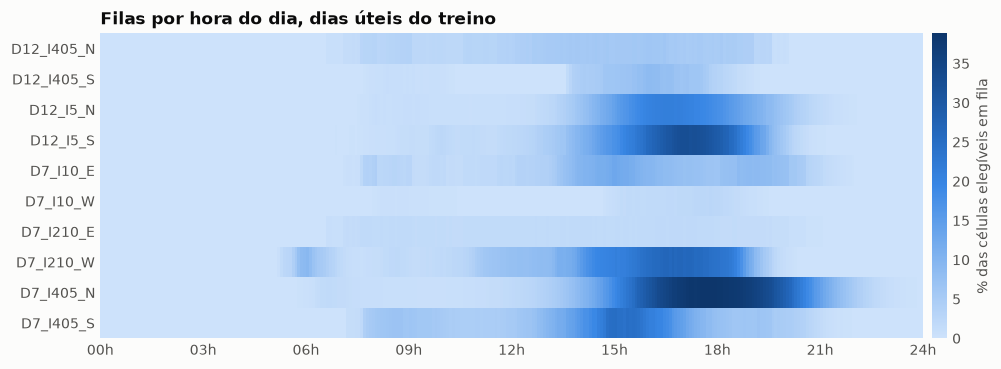

In [8]:
perfil = pd.DataFrame(perfil_fila).T
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(perfil.to_numpy(), aspect="auto", cmap=LinearSegmentedColormap.from_list("azul", AZUL),
               interpolation="nearest", vmin=0)
ax.set_yticks(range(len(perfil)), perfil.index)
ax.set_xticks(np.arange(0, 289, 36) - 0.5, [f"{h:02d}h" for h in range(0, 25, 3)])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.01, fraction=0.025)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=TINTA_MUDA, labelcolor=TINTA_2, length=0)
cb.set_label("% das células elegíveis em fila", color=TINTA_2)
ax.set_title("Filas por hora do dia, dias úteis do treino")
plt.show()

Os corredores são muito diferentes entre si. O D7_I405_N passa ~10% do tempo em fila e 4 de cada 5 estações enfileiram em algum momento; o D7_I10_W e o D7_I210_E quase nunca saem do fluxo livre. As filas se concentram nos picos (manhã ou tarde, conforme o sentido), mas fins de semana enfileiram tanto quanto dias úteis, o que não acontece em rodovias reais.

In [9]:
semana, mes = [], []
for p in PAINEIS:
    fd = None
    for split in SPLITS:
        z = carrega(p, split)
        if fd is None:
            fd = rede(p, z["link_id"])
            faixas, vlivre = fd.lanes.to_numpy(np.float32), fd.free_speed_kmh.to_numpy(np.float32)
        vis = ~np.isnan(z["v_pub"]) & (z["eleg"] == 1)  # só o que é publicado, para comparar splits
        fila = (z["v_pub"] <= 0.6 * vlivre) & vis
        meses = pd.Series(z["dias"]).str.slice(0, 7).to_numpy()
        for m in np.unique(meses):
            d = meses == m
            mes.append({"painel": p, "mês": m, "fila_%": 100 * fila[d].sum() / vis[d].sum(),
                        "q_faixa": np.nanmean(np.where(vis[d], z["q_pub"][d] / faixas, np.nan))})
        if split == "train":
            dsem = pd.to_datetime(pd.Series(z["dias"])).dt.day_of_week.to_numpy()
            for w, nome in enumerate(["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]):
                d = dsem == w
                semana.append({"painel": p, "dia": nome, "fila_%": 100 * fila[d].sum() / vis[d].sum(),
                               "q_faixa": np.nanmean(np.where(vis[d], z["q_pub"][d] / faixas, np.nan))})
semana, mes = pd.DataFrame(semana), pd.DataFrame(mes)
print("Fluxo médio por faixa (veic/h) por dia da semana, treino:")
display(semana.pivot(index="painel", columns="dia", values="q_faixa")
        [["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]].round(0))
print("Células em fila (%) por mês; 2031-03 é a validação e 2031-04 o privado:")
mes.pivot(index="painel", columns="mês", values="fila_%").round(1)

Fluxo médio por faixa (veic/h) por dia da semana, treino:


dia,seg,ter,qua,qui,sex,sáb,dom
painel,,,,,,,
D12_I405_N,846.0,856.0,859.0,864.0,868.0,822.0,769.0
D12_I405_S,954.0,959.0,1006.0,1012.0,1044.0,954.0,849.0
D12_I5_N,884.0,889.0,893.0,916.0,896.0,895.0,868.0
D12_I5_S,919.0,934.0,958.0,943.0,977.0,962.0,852.0
D7_I10_E,923.0,956.0,979.0,1002.0,1014.0,960.0,867.0
D7_I10_W,985.0,975.0,1004.0,1013.0,1032.0,961.0,878.0
D7_I210_E,813.0,829.0,833.0,837.0,853.0,819.0,762.0
D7_I210_W,859.0,858.0,866.0,879.0,897.0,853.0,798.0
D7_I405_N,1007.0,1041.0,982.0,997.0,1055.0,991.0,938.0


Células em fila (%) por mês; 2031-03 é a validação e 2031-04 o privado:


mês,2030-06,2030-07,2030-08,2030-09,2030-10,2030-11,2030-12,2031-01,2031-02,2031-03,2031-04
painel,,,,,,,,,,,
D12_I405_N,2.2,2.3,2.1,2.0,2.0,2.2,2.0,2.0,2.0,1.8,2.4
D12_I405_S,1.5,1.0,1.6,1.3,1.3,0.9,1.2,1.3,1.3,0.7,2.2
D12_I5_N,5.4,3.6,5.0,5.8,3.8,7.0,4.8,6.3,4.2,2.2,3.2
D12_I5_S,5.1,7.9,7.3,7.6,6.6,5.5,6.1,6.5,4.2,4.8,6.2
D7_I10_E,3.0,2.9,3.0,3.2,2.9,2.8,3.8,3.7,2.2,2.9,3.7
D7_I10_W,0.4,0.2,0.5,0.5,0.4,0.3,0.1,0.4,0.4,0.5,0.4
D7_I210_E,0.8,0.9,0.9,0.9,0.9,0.9,0.8,0.9,0.9,0.9,1.0
D7_I210_W,7.1,6.6,6.6,6.6,6.8,6.7,6.7,6.9,6.0,5.2,4.3
D7_I405_N,9.3,10.8,10.8,9.1,12.7,7.4,9.3,7.1,9.9,8.0,7.0


O padrão semanal é fraco: o fluxo cai uns 10% no domingo e sobe na sexta, e só. Não há tendência ao longo dos nove meses de treino, e os meses de validação e privado ficam dentro da variação do treino (o D12_I5_N enfileira menos em março e abril; o D7_I405_S, mais). Para a tarefa 1 isso significa que o perfil histórico serve como apoio, mas a informação útil está no próprio dia.

### Um dia com fila, antes e depois da máscara

O dia de regime R3 com mais fila no D7_I405_N. À esquerda a camada completa; à direita a camada publicada, com as células apagadas em branco.

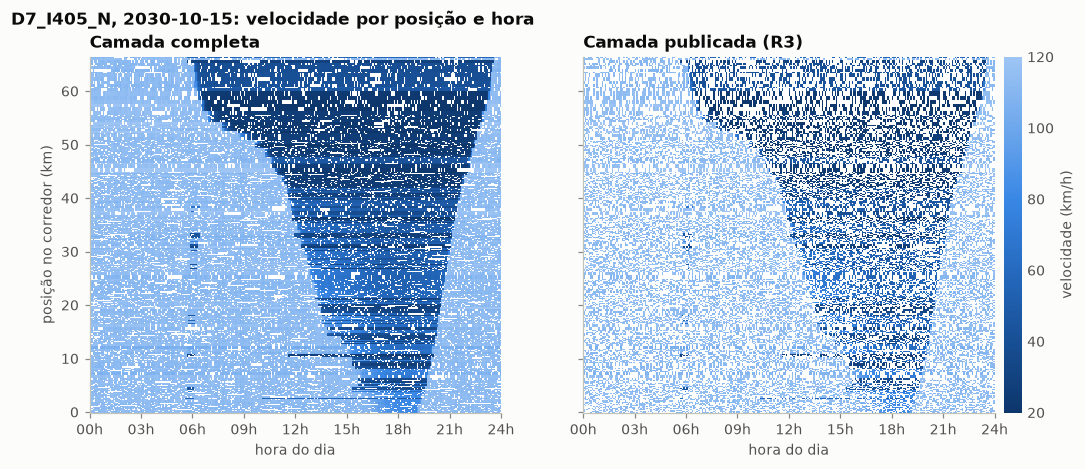

In [10]:
p = "D7_I405_N"
z = carrega(p)
fd = rede(p, z["link_id"])
vlivre = fd.free_speed_kmh.to_numpy(np.float32)
fila_dia = ((z["v"] <= 0.6 * vlivre) & (z["eleg"] == 1)).mean(axis=(1, 2))
d = int(np.flatnonzero(z["regime"] == "R3")[np.argmax(fila_dia[z["regime"] == "R3"])])
mp = z["milepost"].astype(float)
borda_mp = np.concatenate([[mp[0] - 0.1], (mp[1:] + mp[:-1]) / 2, [mp[-1] + 0.1]])
borda_t = np.arange(289) / 12
cmap_v = LinearSegmentedColormap.from_list("vel", AZUL[1:][::-1])  # fluxo livre em azul médio, apagado em branco
cmap_v.set_bad("#ffffff")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (camada, titulo) in zip(axes, [("v", "Camada completa"), ("v_pub", "Camada publicada (R3)")]):
    m = ax.pcolormesh(borda_t, borda_mp, z[camada][d].T, cmap=cmap_v, vmin=20, vmax=120, rasterized=True)
    ax.set_title(titulo)
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}h" for h in range(0, 25, 3)])
    ax.set_xlabel("hora do dia")
axes[0].set_ylabel("posição no corredor (km)")
cb = fig.colorbar(m, ax=axes, pad=0.01, fraction=0.025)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=TINTA_MUDA, labelcolor=TINTA_2, length=0)
cb.set_label("velocidade (km/h)", color=TINTA_2)
fig.suptitle(f"{p}, {z['dias'][d]}: velocidade por posição e hora", x=0.06, ha="left",
             fontsize=11, fontweight="bold")
plt.show()

As filas aparecem como manchas escuras que crescem para trás (para posições menores) com o tempo: a onda de choque que sobe o corredor enquanto a demanda supera a capacidade do gargalo. Mesmo com metade das células apagadas, a forma das manchas continua legível na camada publicada. É essa estrutura espaço-temporal que um bom reconstrutor precisa aproveitar.

## 5. Diagrama fundamental empírico

A tarefa 3 deriva a densidade como `k = q/v` e compara cada célula com o diagrama triangular de cada link: ramo livre `q = v_livre·k` até a densidade crítica `k_c = capacidade / v_livre`, e ramo congestionado decrescendo até `k_jam`. Abaixo, as células elegíveis do treino de duas estações com muita fila, por faixa, com o diagrama publicado em `fd_parameters.csv` por cima.

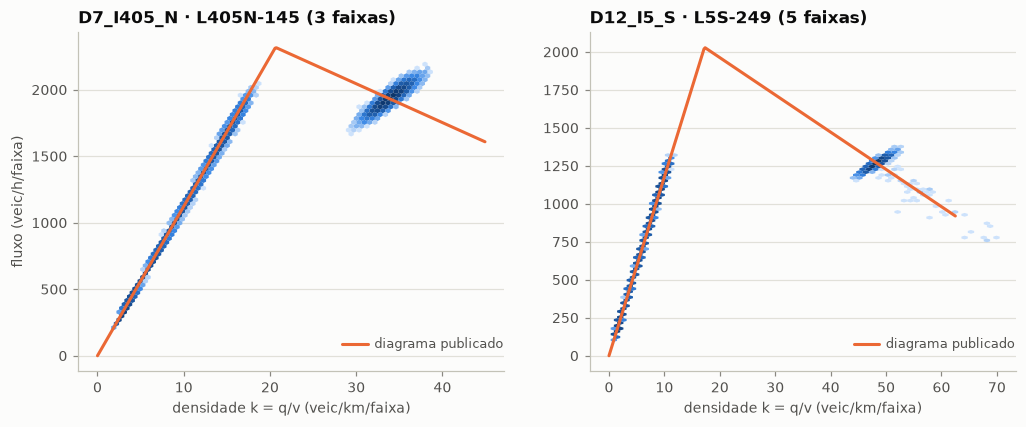

In [11]:
def estacao_mais_congestionada(painel):
    z = carrega(painel)
    fd = rede(painel, z["link_id"])
    fila = (z["v"] <= 0.6 * fd.free_speed_kmh.to_numpy(np.float32)) & (z["eleg"] == 1)
    s = int(np.argmax(fila.mean(axis=(0, 1))))
    e = z["eleg"][:, :, s] == 1
    return z["link_id"][s], fd.iloc[s], z["v"][:, :, s][e], z["q"][:, :, s][e]


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cmap_h = LinearSegmentedColormap.from_list("azul", AZUL)
for ax, painel in zip(axes, ["D7_I405_N", "D12_I5_S"]):
    link, par, v, q = estacao_mais_congestionada(painel)
    faixas = par.lanes
    q_f, k_f = q / faixas, (q / faixas) / np.maximum(v, 1)
    ax.hexbin(k_f, q_f, gridsize=60, bins="log", mincnt=1, cmap=cmap_h, linewidths=0)
    cap, vl = par.capacity_vph / faixas, par.free_speed_kmh
    kc, kj = cap / vl, par.k_jam / faixas
    k = np.linspace(0, min(kj, np.percentile(k_f, 99.9) * 1.2), 300)
    ax.plot(k, np.where(k <= kc, vl * k, cap * (kj - k) / (kj - kc)), color=SERIES[1], lw=2,
            solid_capstyle="round")
    # chave curta no canto vazio (densidade alta, fluxo baixo)
    ax.plot([0.62, 0.68], [0.08, 0.08], transform=ax.transAxes, color=SERIES[1], lw=2,
            solid_capstyle="round")
    ax.text(0.695, 0.08, "diagrama publicado", transform=ax.transAxes, va="center",
            color=TINTA_2, fontsize=8.5)
    ax.set_title(f"{painel} · {link} ({faixas:.0f} faixas)")
    ax.set_xlabel("densidade k = q/v (veic/km/faixa)")
    ax.grid(True, axis="y")
    ax.set_axisbelow(True)
axes[0].set_ylabel("fluxo (veic/h/faixa)")
plt.show()

In [12]:
diag = []
for p in PAINEIS:
    z = carrega(p)
    fd = rede(p, z["link_id"])
    e = z["eleg"] == 1
    vlivre = fd.free_speed_kmh.to_numpy(np.float32)
    q995 = np.nanpercentile(np.where(e, z["q"], np.nan), 99.5, axis=(0, 1))
    v90 = np.nanpercentile(np.where(e, z["v"], np.nan), 90, axis=(0, 1))
    diag.append({"painel": p, "v_p90_sobre_v_livre": np.median(v90 / vlivre),
                 "q_p99,5_sobre_capacidade": np.median(q995 / fd.capacity_vph.to_numpy()),
                 "links_que_chegam_a_90%_da_cap_%": 100 * (q995 / fd.capacity_vph.to_numpy() > 0.9).mean()})
pd.DataFrame(diag).set_index("painel").round(2)

,v_p90_sobre_v_livre,"q_p99,5_sobre_capacidade",links_que_chegam_a_90%_da_cap_%
painel,,,
D12_I405_N,1.01,0.62,1.12
D12_I405_S,1.01,0.77,29.55
D12_I5_N,1.01,0.80,19.38
D12_I5_S,1.01,0.81,34.00
D7_I10_E,1.01,0.77,18.49
D7_I10_W,1.01,0.80,16.82
D7_I210_E,1.02,0.67,1.68
D7_I210_W,1.02,0.66,22.22
D7_I405_N,1.02,0.98,66.19


As células caem quase exatamente sobre duas retas: o gerador é um modelo de tráfego com diagrama triangular. O ramo livre coincide com o publicado (a velocidade p90 de cada estação fica a 1–2% da `free_speed_kmh`). O ramo congestionado também é uma reta, que no D12_I5_S coincide com a publicada e no D7_I405_N fica um pouco deslocada.

Não há pontos perto do pico: quando a fila chega, a estação salta do ramo livre para o congestionado com o fluxo que o gargalo a jusante deixa passar. Por isso boa parte dos links nunca se aproxima da capacidade publicada (o fluxo p99,5 fica, na mediana, entre 62% e 98% dela).

Para a tarefa 1, a consequência é direta: em fila, velocidade e fluxo de uma célula estão amarrados pelo ramo congestionado, e uma reconstrução que respeite esse vínculo também melhora a tarefa 3.

## 6. Ruído de medida

Se o sinal for suave na escala de 5 minutos, o resíduo `x_t − (x_{t−1} + x_{t+1})/2` mede o ruído: com ruído branco de desvio σ, o resíduo tem desvio σ·√1,5. A tabela usa células cujos dois vizinhos no tempo têm `pct_observed = 100` e separa pelo `pct_observed` da célula central.

In [13]:
ruido, estrutura = [], []
for p in PAINEIS:
    z = carrega(p)
    fd = rede(p, z["link_id"])
    faixas, vlivre = fd.lanes.to_numpy(np.float32), fd.free_speed_kmh.to_numpy(np.float32)
    v, qf, pct, e = z["v"], z["q"] / faixas, z["pct"], z["eleg"] == 1
    res_v = v[:, 1:-1] - 0.5 * (v[:, :-2] + v[:, 2:])
    res_q = qf[:, 1:-1] - 0.5 * (qf[:, :-2] + qf[:, 2:])
    vizinhos_ok = (pct[:, :-2] == 100) & (pct[:, 2:] == 100)
    for nivel in (50, 67, 75, 80, 83, 100):
        c = vizinhos_ok & (pct[:, 1:-1] == nivel)
        ruido.append({"painel": p, "pct_observed": nivel, "n": int(c.sum()),
                      "dp_res_v": np.nanstd(res_v[c]), "dp_res_q_faixa": np.nanstd(res_q[c])})
    livre = e[:, 1:-1] & (v[:, 1:-1] > 0.8 * vlivre)
    fila = e[:, 1:-1] & (v[:, 1:-1] <= 0.6 * vlivre)
    ok = ~np.isnan(res_v[:, :, :-1]) & ~np.isnan(res_v[:, :, 1:])
    okq = ~np.isnan(res_q[:, :, :-1]) & ~np.isnan(res_q[:, :, 1:])
    q_c = qf[:, 1:-1]
    estrutura.append({
        "painel": p,
        "dp_res_v_livre": np.nanstd(res_v[livre]), "dp_res_v_fila": np.nanstd(res_v[fila]),
        "dp_res_q_<500": np.nanstd(res_q[livre & (q_c < 500)]),
        "dp_res_q_1000-1500": np.nanstd(res_q[livre & (q_c >= 1000) & (q_c < 1500)]),
        "dp_res_q_>2000": np.nanstd(res_q[livre & (q_c >= 2000)]),
        "corr_res_v_vizinhas": np.corrcoef(res_v[:, :, :-1][ok], res_v[:, :, 1:][ok])[0, 1],
        "corr_res_q_vizinhas": np.corrcoef(res_q[:, :, :-1][okq], res_q[:, :, 1:][okq])[0, 1],
    })
ruido = pd.DataFrame(ruido)
por_pct = ruido.groupby("pct_observed").agg(n=("n", "sum"), dp_res_v=("dp_res_v", "mean"),
                                            dp_res_q_faixa=("dp_res_q_faixa", "mean"))
display(por_pct.round(2))
pd.DataFrame(estrutura).set_index("painel").round(2)

,n,dp_res_v,dp_res_q_faixa
pct_observed,,,
50,599206,2.33,40.04
67,342679,2.32,39.49
75,3103008,2.31,39.23
80,2411243,2.31,39.13
83,1406329,2.31,39.14
100,33906181,2.29,38.97


,dp_res_v_livre,dp_res_v_fila,dp_res_q_<500,dp_res_q_1000-1500,dp_res_q_>2000,corr_res_v_vizinhas,corr_res_q_vizinhas
painel,,,,,,,
D12_I405_N,1.50,7.20,17.33,34.22,61.87,0.59,0.34
D12_I405_S,1.60,8.18,21.65,54.29,63.50,0.44,0.25
D12_I5_N,1.78,5.37,13.31,37.47,93.44,0.60,0.31
D12_I5_S,1.97,5.78,16.06,39.02,107.87,0.48,0.32
D7_I10_E,2.15,7.74,15.78,40.47,156.80,0.61,0.18
D7_I10_W,1.56,5.78,15.05,38.54,56.57,0.35,0.24
D7_I210_E,2.10,5.98,14.00,44.66,126.31,0.40,0.10
D7_I210_W,2.39,5.83,14.32,43.48,87.02,0.41,0.18
D7_I405_N,2.59,4.02,18.93,52.99,118.33,0.48,0.26


Três conclusões:

- **Células com `pct_observed` baixo são tão boas quanto as completas.** O ruído é o mesmo de 50% a 100%. As células inelegíveis não são pontuadas, mas os valores delas servem de evidência.
- **O ruído depende do estado.** Em fila o resíduo da velocidade é de 1,5 a 5 vezes maior que em fluxo livre. O ruído do fluxo cresce com o próprio fluxo, de ~15 veic/h/faixa abaixo de 500 para mais de 50 acima de 2.000.
- **Parte do resíduo é dinâmica real.** O resíduo de estações vizinhas no mesmo instante tem correlação de 0,35–0,6 na velocidade, então os vizinhos espaciais trazem informação que a série da própria estação não tem.

Pelo desvio do resíduo, o ruído branco de medida fica em torno de σ ≈ 1,9 km/h na velocidade e 32 veic/h/faixa no fluxo. Nenhum método prevê esse ruído, e só ele já limita o score:

In [14]:
sig_v = por_pct.loc[100, "dp_res_v"] / np.sqrt(1.5)
sig_q = por_pct.loc[100, "dp_res_q_faixa"] / np.sqrt(1.5)
teto = 0.54 * (1 - sig_v / 25) + 0.46 * (1 - sig_q / 600)
print(f"σ_v ≈ {sig_v:.2f} km/h, σ_q ≈ {sig_q:.1f} veic/h/faixa → S_state máximo ≈ {teto:.3f}")

σ_v ≈ 1.87 km/h, σ_q ≈ 31.8 veic/h/faixa → S_state máximo ≈ 0.935


O valor é aproximado: o resíduo também carrega dinâmica real, então o ruído verdadeiro é um pouco menor e o teto, um pouco maior.

## 7. Faixas: a armadilha do avaliador

O avaliador divide o fluxo pelas faixas de `fd_parameters.csv`. Em alguns links esse número é menor que o da topologia e o fluxo por faixa resultante passa do fisicamente possível (~2.400 veic/h/faixa). Nesses links o erro de fluxo pesa o dobro, ou mais, no RMSE.

In [15]:
faixas_tab, peso = [], []
for p in PAINEIS:
    z = carrega(p)
    fd = rede(p, z["link_id"])
    topo = pd.read_csv(REL / f"corridors/{p}/network/lwr_mainline_topology.csv").set_index("link_id")
    topo = topo.reindex(z["link_id"])
    e = z["eleg"] == 1
    q99 = np.nanpercentile(np.where(e, z["q"], np.nan), 99, axis=(0, 1))
    estranhos = q99 / fd.lanes.to_numpy() > 2600
    for s in np.flatnonzero(estranhos):
        faixas_tab.append({"painel": p, "link": z["link_id"][s], "faixas_fd": fd.lanes.iloc[s],
                           "faixas_topologia": topo.lanes.iloc[s], "q_p99_total": q99[s],
                           "q_p99_por_faixa_fd": q99[s] / fd.lanes.iloc[s]})
    # quanto do erro de fluxo de uma interpolação simples cada estação concentra
    faixas = fd.lanes.to_numpy(np.float32)
    err = ((0.5 * (z["q"][:, :-2] + z["q"][:, 2:]) - z["q"][:, 1:-1]) / faixas) ** 2
    por_est = np.nansum(np.where(e[:, 1:-1], err, 0), axis=(0, 1))
    top = np.argsort(por_est)[::-1]
    peso.append({"painel": p, "estação_que_mais_pesa": z["link_id"][top[0]],
                 "faixas_fd": fd.lanes.iloc[top[0]],
                 "parcela_do_erro_%": 100 * por_est[top[0]] / por_est.sum(),
                 "parcela_esperada_%": 100 / len(por_est)})
display(pd.DataFrame(faixas_tab).round(0))
pd.DataFrame(peso).set_index("painel").round(1)

,painel,link,faixas_fd,faixas_topologia,q_p99_total,q_p99_por_faixa_fd
0,D7_I10_E,L10E-084,1.0,2,5971.0,5971.0
1,D7_I210_E,L210E-012,1.0,2,4746.0,4746.0
2,D7_I210_E,L210E-013,1.0,2,4751.0,4751.0


,estação_que_mais_pesa,faixas_fd,parcela_do_erro_%,parcela_esperada_%
painel,,,,
D12_I405_N,L405N-003,3.0,3.7,1.1
D12_I405_S,L405S-097,4.0,3.6,2.3
D12_I5_N,L5N-100,4.0,0.8,0.4
D12_I5_S,L5S-067,4.0,2.8,1.0
D7_I10_E,L10E-084,1.0,10.1,0.7
D7_I10_W,L10W-197,3.0,2.4,0.9
D7_I210_E,L210E-012,1.0,4.3,0.3
D7_I210_W,L210W-106,2.0,3.9,1.2
D7_I405_N,L405N-272,3.0,0.6,0.3


No D7_I10_E, um único link (L10E-084, uma faixa no `fd_parameters.csv` e duas na topologia) responde por 10% do erro quadrático de fluxo do corredor inteiro. O modelo deve ser treinado com o erro no fluxo por faixa, dividido pelas faixas do `fd_parameters.csv`, para dar a esses links o peso que o avaliador dá.

## 8. Quanto métodos simples já acertam

Referências calculadas sobre os alvos do treino, com a métrica oficial, usando só a camada publicada:

- **média histórica**: média por estação, dia da semana e instante, a mesma ideia do baseline oficial (0,6929 na validação);
- **temporal**: interpolação linear na série da própria estação, no mesmo dia (só com células elegíveis, ou com todas as visíveis);
- **espacial**: interpolação linear ao longo do corredor, no mesmo instante;
- **média temporal + espacial**: a média das duas;
- **por canal**: velocidade da interpolação temporal e fluxo da média temporal + espacial.

Onde a interpolação não tem vizinho dos dois lados, usa o lado que existe; sem nenhum, a média histórica.

In [16]:
def interpola(val, vis, eixo):
    # Interpolação linear pelo índice ao longo de `eixo`, usando só as células visíveis.
    v, m = np.moveaxis(val, eixo, -1), np.moveaxis(vis, eixo, -1)
    n = v.shape[-1]
    idx = np.arange(n, dtype=np.int32)
    esq = np.maximum.accumulate(np.where(m, idx, -1), axis=-1)
    dir_ = np.minimum.accumulate(np.where(m, idx, n)[..., ::-1], axis=-1)[..., ::-1]
    ve = np.take_along_axis(v, np.clip(esq, 0, n - 1), -1)
    vd = np.take_along_axis(v, np.clip(dir_, 0, n - 1), -1)
    tem_e, tem_d = esq >= 0, dir_ < n
    w = np.where(tem_e & tem_d, (idx - esq) / np.maximum(dir_ - esq, 1), np.where(tem_e, 0, 1)).astype(np.float32)
    out = np.where(tem_e | tem_d, (1 - w) * ve + w * vd, np.nan)
    return np.moveaxis(out, -1, eixo)


refs, erro_fila = [], []
for p in PAINEIS:
    z = carrega(p)
    fd = rede(p, z["link_id"])
    faixas = np.broadcast_to(fd.lanes.to_numpy(np.float32), z["v"].shape)
    vlivre = fd.free_speed_kmh.to_numpy(np.float32)
    vp, qp = np.nan_to_num(z["v_pub"]), np.nan_to_num(z["q_pub"])
    vis = ~np.isnan(z["v_pub"])
    vis_el = vis & (z["eleg"] == 1)
    dsem = pd.to_datetime(pd.Series(z["dias"])).dt.day_of_week.to_numpy()
    hist_v = np.empty_like(vp)
    hist_q = np.empty_like(qp)
    for w in range(7):
        d = dsem == w
        cnt = np.maximum(vis_el[d].sum(0), 1)
        hist_v[d] = (np.where(vis_el[d], vp[d], 0).sum(0) / cnt)[None]
        hist_q[d] = (np.where(vis_el[d], qp[d], 0).sum(0) / cnt)[None]

    def completa(prev, hist):
        return np.where(np.isnan(prev), hist, prev)

    t_v, t_q = completa(interpola(vp, vis, 1), hist_v), completa(interpola(qp, vis, 1), hist_q)
    e_v, e_q = completa(interpola(vp, vis, 2), hist_v), completa(interpola(qp, vis, 2), hist_q)
    metodos = {
        "média histórica": (hist_v, hist_q),
        "temporal (só elegíveis)": (completa(interpola(vp, vis_el, 1), hist_v),
                                    completa(interpola(qp, vis_el, 1), hist_q)),
        "temporal": (t_v, t_q),
        "espacial": (e_v, e_q),
        "média temporal + espacial": (0.5 * (t_v + e_v), 0.5 * (t_q + e_q)),
        "por canal": (t_v, 0.5 * (t_q + e_q)),
    }
    for nome, (pv, pq_) in metodos.items():
        for r in REGIMES:
            a = z["alvo"] & (z["regime"] == r)[:, None, None]
            rv, rq, s = s_state(pv[a], pq_[a], z["v"][a], z["q"][a], faixas[a])
            refs.append({"painel": p, "método": nome, "regime": r, "rmse_v": rv, "rmse_q_faixa": rq, "S": s})
    a = z["alvo"]
    fila = a & (z["v"] <= 0.6 * vlivre)
    ev = (t_v - z["v"]) ** 2
    erro_fila.append({"painel": p, "alvos_em_fila_%": 100 * fila.sum() / a.sum(),
                      "erro_v_em_fila_%": 100 * ev[fila].sum() / ev[a].sum(),
                      "rmse_v_livre": np.sqrt(ev[a & ~fila].mean()), "rmse_v_fila": np.sqrt(ev[fila].mean())})
    del metodos, t_v, t_q, e_v, e_q, hist_v, hist_q
refs = pd.DataFrame(refs)
ordem = ["média histórica", "espacial", "média temporal + espacial", "temporal (só elegíveis)", "temporal", "por canal"]
por_regime = refs.groupby(["método", "regime"])[["rmse_v", "rmse_q_faixa", "S"]].mean().unstack().loc[ordem]
por_painel = refs.groupby(["método", "painel"]).S.mean().unstack(0)[ordem]
geral = por_painel.groupby(familia).mean().mean()
display(por_regime.round(3))
display(por_painel.round(3))
print("S_state geral (média das famílias):")
geral.round(4)

rmse_v               rmse_q_faixa                      S              
regime                        R1     R2     R3           R1      R2      R3     R1     R2     R3
método                                                                                          
média histórica            9.589  9.471  9.723       93.172  94.770  95.606  0.721  0.723  0.717
espacial                   7.429  7.676  8.183       39.105  39.840  41.671  0.810  0.804  0.791
média temporal + espacial  4.110  4.241  4.565       34.967  35.574  37.443  0.884  0.881  0.873
temporal (só elegíveis)    2.609  2.686  3.075       43.069  44.266  48.429  0.911  0.908  0.896
temporal                   2.523  2.587  2.896       42.079  43.118  46.635  0.913  0.911  0.902
por canal                  2.523  2.587  2.896       34.967  35.574  37.443  0.919  0.917  0.909

método,média histórica,espacial,média temporal + espacial,temporal (só elegíveis),temporal,por canal
painel,,,,,,
D12_I405_N,0.818,0.789,0.880,0.924,0.927,0.934
D12_I405_S,0.773,0.821,0.888,0.909,0.912,0.920
D12_I5_N,0.609,0.842,0.900,0.908,0.912,0.919
D12_I5_S,0.617,0.724,0.843,0.898,0.903,0.907
D7_I10_E,0.713,0.822,0.889,0.901,0.904,0.910
D7_I10_W,0.831,0.875,0.920,0.931,0.932,0.939
D7_I210_E,0.883,0.872,0.914,0.918,0.919,0.924
D7_I210_W,0.773,0.661,0.812,0.894,0.898,0.902
D7_I405_N,0.538,0.833,0.884,0.878,0.883,0.892


S_state geral (média das famílias):


método
média histórica              0.720
espacial                     0.801
média temporal + espacial    0.879
temporal (só elegíveis)      0.905
temporal                     0.909
por canal                    0.915
dtype: float64

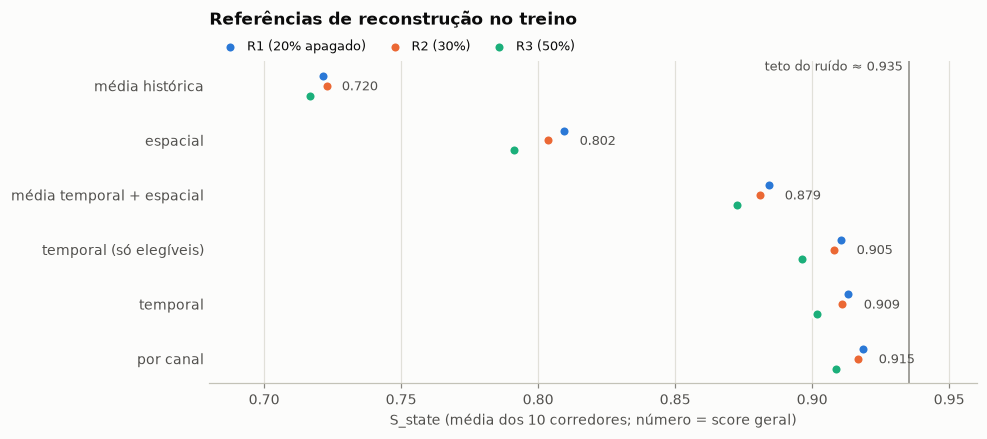

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(ordem))
for k, (r, rot) in enumerate(zip(REGIMES, ["R1 (20% apagado)", "R2 (30%)", "R3 (50%)"])):
    ax.scatter(por_regime[("S", r)].to_numpy(), y + (k - 1) * 0.18, s=46, color=SERIES[k],
               edgecolor=SUPERFICIE, linewidth=1.5, zorder=3, label=rot)
ax.axvline(teto, color=TINTA_MUDA, lw=1)
ax.annotate(f"teto do ruído ≈ {teto:.3f}", xy=(teto, -0.35), xytext=(-4, 0),
            textcoords="offset points", ha="right", va="center", color=TINTA_2, fontsize=8.5)
for yi, m in zip(y, ordem):
    ax.annotate(f"{geral[m]:.3f}", xy=(por_regime.loc[m, "S"].max(), yi), xytext=(10, -3),
                textcoords="offset points", color=TINTA_2, fontsize=8.5)
ax.set_yticks(y, ordem)
ax.invert_yaxis()
ax.set_xlim(0.68, 0.96)
ax.set_xlabel("S_state (média dos 10 corredores; número = score geral)")
ax.grid(True, axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5, handletextpad=0.3,
          columnspacing=1.2, borderaxespad=0.2)
ax.set_title("Referências de reconstrução no treino", pad=24)
plt.show()

In [18]:
print("Erro da interpolação temporal de velocidade: fila x fluxo livre")
pd.DataFrame(erro_fila).set_index("painel").round(2)

Erro da interpolação temporal de velocidade: fila x fluxo livre


,alvos_em_fila_%,erro_v_em_fila_%,rmse_v_livre,rmse_v_fila
painel,,,,
D12_I405_N,2.13,36.87,1.75,9.08
D12_I405_S,1.23,31.13,1.82,10.94
D12_I5_N,5.12,38.56,2.21,7.53
D12_I5_S,6.20,39.57,2.47,7.77
D7_I10_E,3.10,34.54,2.44,9.91
D7_I10_W,0.37,10.64,1.67,9.44
D7_I210_E,0.87,10.58,2.20,8.07
D7_I210_W,6.60,34.29,2.75,7.47
D7_I405_N,9.97,30.04,3.09,6.09


## Conclusões para a modelagem

1. **A informação está no próprio dia.** Interpolar a série da estação leva o score de 0,720 para 0,909. O perfil histórico deve entrar só como apoio, nos trechos longos sem observação.
2. **Velocidade e fluxo pedem estratégias diferentes.** O erro de velocidade vem das filas (de 10% a 40% do erro em menos de 10% dos alvos), e quem mostra a onda de choque são os vizinhos espaciais. O erro de fluxo vem do ruído em fluxo livre, e o fluxo, que se conserva ao longo do corredor, ganha com a média entre estações vizinhas.
3. **Usar todas as células visíveis**, inclusive as de `pct_observed < 75`: elas têm o mesmo ruído das outras.
4. **Calcular o erro de treino no fluxo por faixa**, com as faixas de `fd_parameters.csv`, para pesar cada link como o avaliador pesa.
5. **Validar por blocos de dias e simular no treino os apagões da tarefa 2**, para que o erro nesses trechos apareça na validação local.
6. **Sobra pouco espaço para ganhar**: de 0,915 até um teto perto de 0,935. O próximo passo é um modelo que combine vizinhos no tempo e no espaço (por exemplo, gradient boosting sobre features de vizinhança), comparado com estas referências, e uma checagem de que a reconstrução respeita o diagrama fundamental em fila.